<a href="https://colab.research.google.com/github/LizaMilovanova/Labs/blob/main/%D0%9B%D0%A0_8_%D0%9C%D1%96%D0%BB%D0%BE%D0%B2%D0%B0%D0%BD%D0%BE%D0%B2%D0%B0_%D0%A4%D0%86%D0%A2_4_8_%D0%9C%D0%9D_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [ ]:
# Завантаження датасету
iris = load_iris()

# Створення DataFrame з назвами колонок (ознак)
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)

# Виведення перших п'яти рядків
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

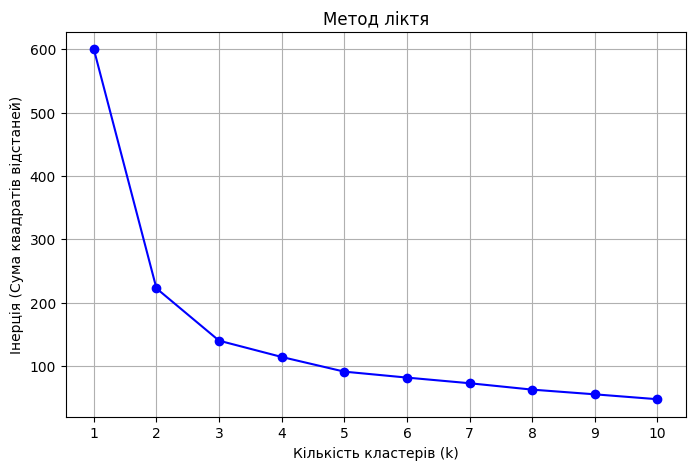

In [ ]:
# Стандартизація даних
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# Обчислення інерції для різної кількості кластерів (від 1 до 10)
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Побудова графіка "ліктя"
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.title('Метод ліктя')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Інерція (Сума квадратів відстаней)')
plt.xticks(K_range)
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

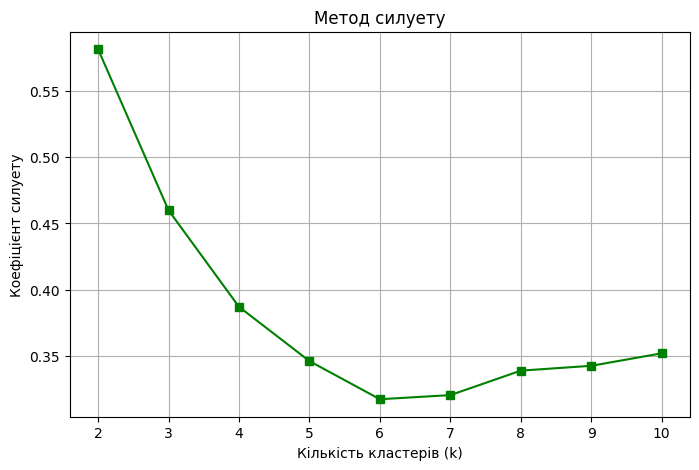

In [ ]:
# Обчислення коефіцієнта силуету для кластерів від 2 до 10
silhouette_scores = []
K_sil = range(2, 11)

for k in K_sil:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    # Обчислення середнього коефіцієнта силуету
    score = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_scores.append(score)

# Побудова графіка методу силуетів
plt.figure(figsize=(8, 5))
plt.plot(K_sil, silhouette_scores, marker='s', linestyle='-', color='g')
plt.title('Метод силуету')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Коефіцієнт силуету')
plt.xticks(K_sil)
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

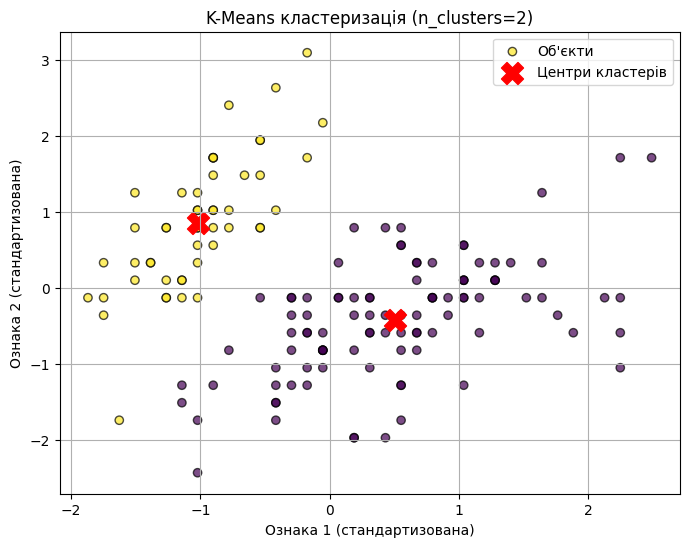

In [ ]:
# 1. Створення та навчання моделі K-Means на 2 кластери
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans_final.fit_predict(X_scaled)

# 2. Отримання координат центрів кластерів
centroids = kmeans_final.cluster_centers_

# 3. Візуалізація
plt.figure(figsize=(8, 6))

# Будуємо точки даних (використовуємо перші дві ознаки: [:, 0] та [:, 1])
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=clusters, cmap='viridis', alpha=0.7, edgecolors='k', label='Об\'єкти')

# Будуємо центри кластерів (червоні хрестики)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=250, label='Центри кластерів')

plt.title('K-Means кластеризація (n_clusters=2)')
plt.xlabel('Ознака 1 (стандартизована)')
plt.ylabel('Ознака 2 (стандартизована)')
plt.legend()
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

За методом ліктя оптимальну кількість кластерів шукають у точці найбільшого "згину" графіка (де падіння інерції різко сповільнюється). На графіку інерції для Iris цей згин прослідковується при k=2 або k=3.
За методом силуетів найкращим вважається розбиття з найвищим значенням коефіцієнта силуету. На побудованому графіку чітко видно, що максимальне значення середнього силуету досягається саме при k=2.

Вибір n_clusters=2 повністю збігається з результатами графіка методу силуетів, який є більш об'єктивною метрикою якості кластеризації. Математично дані Iris найкраще розділяються саме на 2 групи (хоча біологічних видів квітки 3, два з них — Versicolor та Virginica — мають дуже схожі числові характеристики і алгоритмам складно їх розділити без учителя, тому вони зливаються в один великий кластер).

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [ ]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [ ]:
df.columns

Index(['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation',
       'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport',
       'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA',
       'GradeClass'],
      dtype='object')

**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [ ]:
df.isnull().sum()

,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [ ]:
df.duplicated().sum()

np.int64(0)

**2.8. Описова статистика.** Виведіть основні описові статистики.

In [ ]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [ ]:
# Формування ознак (X) та цільової змінної (y)
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']

# Поділ даних на тренувальну та тестову вибірки (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Стандартизація ознак
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [ ]:
# Задаємо сітку гіперпараметрів
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

# Ініціалізація моделі
rf = RandomForestClassifier(random_state=42)

# Налаштування GridSearchCV (5 згорток)
grid_rf = GridSearchCV(rf, param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1)

# Навчання моделі
grid_rf.fit(X_train_scaled, y_train)

# Передбачення на тестовій вибірці
y_pred_rf = grid_rf.predict(X_test_scaled)
test_accuracy_rf = accuracy_score(y_test, y_pred_rf)

# Виведення результатів
print("Найкращі параметри Random Forest:", grid_rf.best_params_)
print(f"Середня CV-точність: {grid_rf.best_score_:.4f}")
print(f"Тестова accuracy: {test_accuracy_rf:.4f}")

Найкращі параметри Random Forest: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV-точність: 0.9237
Тестова accuracy: 0.9144


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [ ]:
# Задаємо сітку гіперпараметрів
param_grid_lr = {
    'C': [0.1, 1, 10],
    'penalty': ['l1', 'l2']
}

# Ініціалізація моделі (використовуємо solver='saga', max_iter збільшено для уникнення помилок збіжності)
lr = LogisticRegression(solver='saga', max_iter=2000, random_state=42)

# Налаштування GridSearchCV (5 згорток)
grid_lr = GridSearchCV(lr, param_grid_lr, cv=5, scoring='accuracy', n_jobs=-1)

# Навчання моделі
grid_lr.fit(X_train_scaled, y_train)

# Передбачення на тестовій вибірці
y_pred_lr = grid_lr.predict(X_test_scaled)
test_accuracy_lr = accuracy_score(y_test, y_pred_lr)

# Виведення результатів
print("Найкращі параметри Logistic Regression:", grid_lr.best_params_)
print(f"Середня CV-точність: {grid_lr.best_score_:.4f}")
print(f"Тестова accuracy: {test_accuracy_lr:.4f}")

Найкращі параметри Logistic Regression: {'C': 0.1, 'penalty': 'l1'}
Середня CV-точність: 0.7961
Тестова accuracy: 0.7662


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [ ]:
# Задаємо сітку гіперпараметрів для SVM
param_grid_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}

# Ініціалізація моделі SVM
svm = SVC(random_state=42)

# Налаштування GridSearchCV (5 згорток)
grid_svm = GridSearchCV(svm, param_grid_svm, cv=5, scoring='accuracy', n_jobs=-1)

# Навчання моделі на стандартизованих тренувальних даних
grid_svm.fit(X_train_scaled, y_train)

# Передбачення на тестовій вибірці
y_pred_svm = grid_svm.predict(X_test_scaled)
test_accuracy_svm = accuracy_score(y_test, y_pred_svm)

# Виведення результатів
print("Найкращі параметри SVM:", grid_svm.best_params_)
print(f"Середня CV-точність: {grid_svm.best_score_:.4f}")
print(f"Тестова accuracy: {test_accuracy_svm:.4f}")

Найкращі параметри SVM: {'C': 10, 'kernel': 'linear'}
Середня CV-точність: 0.8620
Тестова accuracy: 0.8288


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [ ]:
# Збираємо метрики моделей у словники
cv_scores = {
    'Random Forest': grid_rf.best_score_,
    'Logistic Regression': grid_lr.best_score_,
    'SVM': grid_svm.best_score_
}

test_scores = {
    'Random Forest': test_accuracy_rf,
    'Logistic Regression': test_accuracy_lr,
    'SVM': test_accuracy_svm
}

print("--- Порівняння точності моделей ---")
for model_name in cv_scores:
    print(f"{model_name}: CV-точність = {cv_scores[model_name]:.4f}, Тестова точність = {test_scores[model_name]:.4f}")

# Знаходимо назву моделі з найбільшою CV-точністю
best_model_name = max(cv_scores, key=cv_scores.get)
print(f"\nНайкраща модель за CV-точністю: {best_model_name}")

# Отримуємо найкращий естіматор для обраної моделі
if best_model_name == 'Random Forest':
    best_model = grid_rf.best_estimator_
elif best_model_name == 'Logistic Regression':
    best_model = grid_lr.best_estimator_
else:
    best_model = grid_svm.best_estimator_

# Робимо прогноз найкращою моделлю та виводимо classification_report
y_pred_best = best_model.predict(X_test_scaled)

print(f"\nClassification Report для найкращої моделі ({best_model_name}):")
print(classification_report(y_test, y_pred_best))

--- Порівняння точності моделей ---
Random Forest: CV-точність = 0.9237, Тестова точність = 0.9144
Logistic Regression: CV-точність = 0.7961, Тестова точність = 0.7662
SVM: CV-точність = 0.8620, Тестова точність = 0.8288

Найкраща модель за CV-точністю: Random Forest

Classification Report для найкращої моделі (Random Forest):
              precision    recall  f1-score   support

         0.0       0.83      0.45      0.59        22
         1.0       0.81      0.88      0.84        49
         2.0       0.94      0.87      0.90        85
         3.0       0.90      0.90      0.90        86
         4.0       0.94      0.99      0.96       237

    accuracy                           0.91       479
   macro avg       0.88      0.82      0.84       479
weighted avg       0.91      0.91      0.91       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

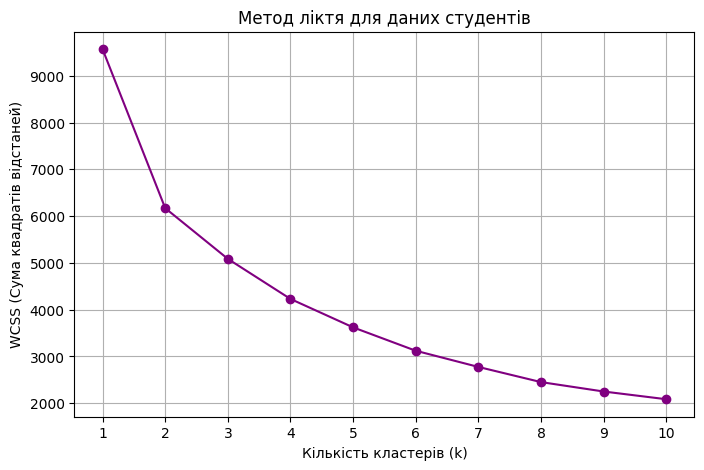

In [ ]:
# Відбираємо вказані числові ознаки
features_cluster = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_students = df[features_cluster]

# Стандартизація даних для кластеризації
scaler_students = StandardScaler()
X_students_scaled = scaler_students.fit_transform(X_students)

# Обчислення WCSS (інерції) для кількості кластерів від 1 до 10
wcss = []
K_range_students = range(1, 11)

for k in K_range_students:
    kmeans_st = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_st.fit(X_students_scaled)
    wcss.append(kmeans_st.inertia_)

# Побудова графіка "ліктя" (WCSS)
plt.figure(figsize=(8, 5))
plt.plot(K_range_students, wcss, marker='o', linestyle='-', color='purple')
plt.title('Метод ліктя для даних студентів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS (Сума квадратів відстаней)')
plt.xticks(K_range_students)
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

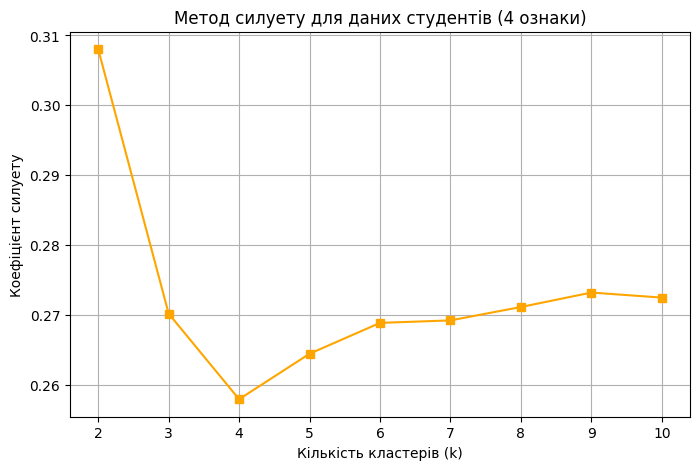

In [ ]:
# Обчислення коефіцієнта силуету для кластерів від 2 до 10
silhouette_scores_st = []
K_sil_st = range(2, 11)

for k in K_sil_st:
    kmeans_st = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_st.fit(X_students_scaled)
    # Обчислюємо силует
    score = silhouette_score(X_students_scaled, kmeans_st.labels_)
    silhouette_scores_st.append(score)

# Побудова графіка методу силуетів
plt.figure(figsize=(8, 5))
plt.plot(K_sil_st, silhouette_scores_st, marker='s', linestyle='-', color='orange')
plt.title('Метод силуету для даних студентів (4 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Коефіцієнт силуету')
plt.xticks(K_sil_st)
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [ ]:
!pip install kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [ ]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [ ]:
# Відкидаємо ідентифікатор та цільову змінну, залишаємо лише ознаки для PCA
X_pca = df.drop(columns=['StudentID', 'GradeClass'])

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [ ]:
# Стандартизація даних
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca)

# Ініціалізація та навчання моделі PCA (на всі компоненти)
pca = PCA(random_state=42)
pca.fit(X_pca_scaled)

# Доля поясненої дисперсії для кожної компоненти
explained_variance = pca.explained_variance_ratio_

print("Доля поясненої дисперсії кожної компоненти:")
print(np.round(explained_variance, 4))

Доля поясненої дисперсії кожної компоненти:
[0.1525 0.0861 0.0827 0.0807 0.0786 0.0779 0.0763 0.076  0.0744 0.0738
 0.0717 0.0675 0.0018]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

In [ ]:
# Формуємо горизонтальну вісь (1, 2, 3, ...)
x_components = range(1, len(explained_variance) + 1)

# Застосовуємо KneeLocator до часток поясненої дисперсії (це спадна, випукла крива)
kl = KneeLocator(x_components, explained_variance, curve='convex', direction='decreasing')
n_components = kl.knee

print(f"Оптимальна кількість компонентів (за ліктем): {n_components}")

Оптимальна кількість компонентів (за ліктем): 2


**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

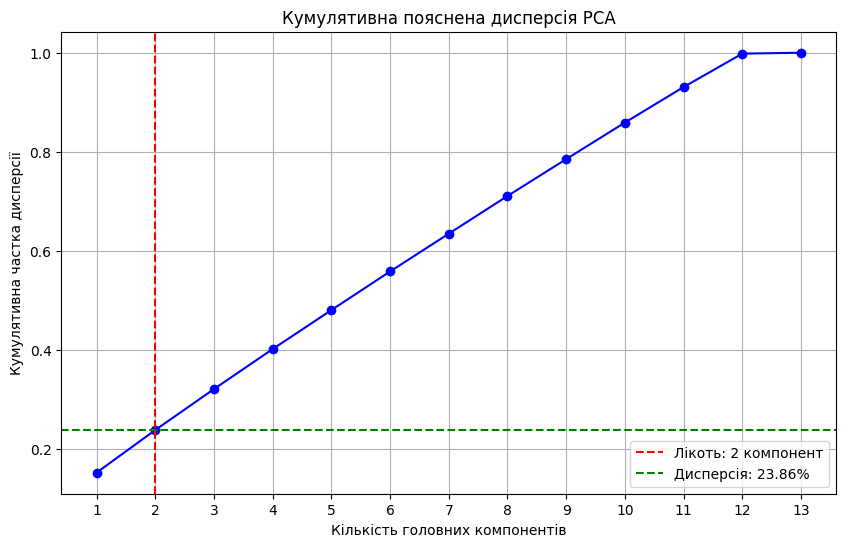

Фактична частина дисперсії для 2 компонентів: 0.2386


In [ ]:
# Обчислення кумулятивної (накопиченої) дисперсії
cumulative_variance = np.cumsum(explained_variance)

# Згідно з умовою: індекс масиву для n_components дорівнює n_components - 1
actual_variance = cumulative_variance[n_components - 1]

# Побудова графіка
plt.figure(figsize=(10, 6))
plt.plot(x_components, cumulative_variance, marker='o', linestyle='-', color='b')

# Позначення знайденої кількості компонентів та дисперсії
plt.axvline(x=n_components, color='red', linestyle='--', label=f'Лікоть: {n_components} компонент')
plt.axhline(y=actual_variance, color='green', linestyle='--', label=f'Дисперсія: {actual_variance:.2%}')

plt.title('Кумулятивна пояснена дисперсія PCA')
plt.xlabel('Кількість головних компонентів')
plt.ylabel('Кумулятивна частка дисперсії')
plt.xticks(x_components)
plt.legend()
plt.grid(True)
plt.show()

# Виведення фактичної частини дисперсії
print(f"Фактична частина дисперсії для {n_components} компонентів: {actual_variance:.4f}")

# Перетворення ознак через PCA на наступний етап (з оптимальною кількістю компонентів)
pca_optimal = PCA(n_components=n_components, random_state=42)
X_pca_final = pca_optimal.fit_transform(X_pca_scaled)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [ ]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

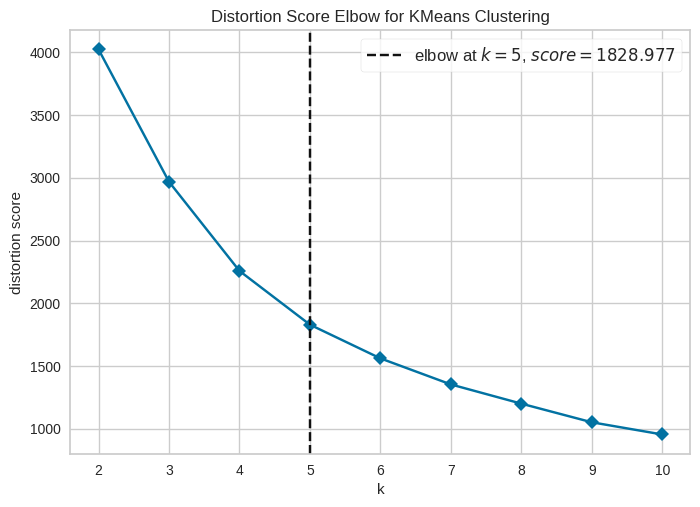

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
# Ініціалізація базової моделі K-Means
kmeans_pca = KMeans(random_state=42, n_init=10)

# Ініціалізація візуалізатора KElbowVisualizer (перевіряємо від 2 до 10 кластерів)
visualizer = KElbowVisualizer(kmeans_pca, k=(2, 11), timings=False)

# Навчання візуалізатора на даних після PCA та побудова графіка
visualizer.fit(X_pca_final)
visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

Визначення кількості кластерів: Автоматизований метод ліктя (KElbowVisualizer) на даних після PCA чітко визначив оптимальну кількість кластерів — 5. Це набагато точніше, ніж шукати "згин" на графіку "на око".   

Класифікація vs Кластеризація: Класифікація — це навчання з учителем, де ми передбачали конкретну цільову оцінку студента (GradeClass). Кластеризація — навчання без учителя: ми прибрали оцінку, і алгоритм K-Means самостійно розділив студентів на 5 груп виключно за подібністю їхніх характеристик

Ефективність PCA: Застосування методу головних компонент (PCA) дозволило зменшити кількість ознак, відкинувши "шум" і залишивши найважливішу частину дисперсії (інформації). Це суттєво оптимізувало роботу алгоритму K-Means на фінальному етапі.